In [3]:

# ============================================================
# PROJECT: ATMOSYNC - WEATHER DATA ANALYSIS
# Using Python, Pandas, NumPy and Matplotlib
# ============================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

print("Libraries imported successfully!")

# ============================================================
# 2. LOAD CSV DATASET
# ============================================================

print("Current folder:", os.getcwd())
print("Available CSV files:", [f for f in os.listdir() if f.endswith(".csv")])

file_path = input("Enter your CSV filename (example: weather_data.csv): ")

df = pd.read_csv(file_path)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

# ============================================================
# 3. DISPLAY BASIC DATA
# ============================================================

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical description:")
display(df.describe(include="all"))

# ============================================================
# 4. CLEAN COLUMN NAMES
# ============================================================

df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

print("\nCleaned column names:")
print(df.columns.tolist())

# ============================================================
# 5. IDENTIFY COMMON COLUMN NAMES
# ============================================================

# This section recognizes common alternative column names.

column_aliases = {
    "location": ["city", "place", "region"],
    "time": ["date", "datetime", "timestamp"],
    "temperature_c": ["temperature", "temp", "temperature_2m"],
    "humidity_percent": ["humidity", "relative_humidity"],
    "wind_speed_kmh": ["wind_speed", "windspeed", "wind"],
    "precipitation_mm": ["precipitation", "rainfall", "rain"],
    "cloud_cover_percent": ["cloud_cover", "cloudcover"]
}

for standard_name, alternatives in column_aliases.items():
    if standard_name not in df.columns:
        for alternative in alternatives:
            if alternative in df.columns:
                df.rename(columns={alternative: standard_name}, inplace=True)
                break

print("\nUpdated column names:")
print(df.columns.tolist())

# ============================================================
# 6. CHECK MISSING VALUES
# ============================================================

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

# ============================================================
# 7. REMOVE DUPLICATE RECORDS
# ============================================================

print("\nDuplicate records before cleaning:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicate records after cleaning:", df.duplicated().sum())

# ============================================================
# 8. CONVERT DATE AND NUMERIC COLUMNS
# ============================================================

if "time" in df.columns:
    df["time"] = pd.to_datetime(df["time"], errors="coerce")

numeric_columns = [
    "temperature_c",
    "humidity_percent",
    "wind_speed_kmh",
    "precipitation_mm",
    "cloud_cover_percent"
]

for column in numeric_columns:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

# Fill missing numeric values with their column median
for column in numeric_columns:
    if column in df.columns:
        df[column] = df[column].fillna(df[column].median())

# Fill missing location values if location exists
if "location" in df.columns:
    df["location"] = df["location"].fillna("Unknown")

print("\nMissing values after cleaning:")
print(df.isnull().sum())

# ============================================================
# 9. DISPLAY CLEANED DATASET
# ============================================================

print("\nCleaned dataset:")
display(df.head())

print("\nFinal dataset shape:", df.shape)

# Save cleaned dataset
df.to_csv("Cleaned_Weather_Data.csv", index=False)

print("Cleaned dataset saved successfully!")

# ============================================================
# 10. TEMPERATURE ANALYSIS
# ============================================================

if "temperature_c" in df.columns:

    print("\nTemperature Analysis")
    print("Average Temperature:", round(df["temperature_c"].mean(), 2), "°C")
    print("Maximum Temperature:", round(df["temperature_c"].max(), 2), "°C")
    print("Minimum Temperature:", round(df["temperature_c"].min(), 2), "°C")

    plt.figure(figsize=(10, 5))
    plt.hist(df["temperature_c"], bins=15, edgecolor="black")
    plt.title("Temperature Distribution")
    plt.xlabel("Temperature (°C)")
    plt.ylabel("Frequency")
    plt.grid(axis="y", alpha=0.3)
    plt.show()

# ============================================================
# 11. HUMIDITY ANALYSIS
# ============================================================

if "humidity_percent" in df.columns:

    print("\nHumidity Analysis")
    print("Average Humidity:", round(df["humidity_percent"].mean(), 2), "%")
    print("Maximum Humidity:", df["humidity_percent"].max(), "%")
    print("Minimum Humidity:", df["humidity_percent"].min(), "%")

    plt.figure(figsize=(10, 5))
    plt.hist(df["humidity_percent"], bins=15, edgecolor="black")
    plt.title("Humidity Distribution")
    plt.xlabel("Humidity (%)")
    plt.ylabel("Frequency")
    plt.grid(axis="y", alpha=0.3)
    plt.show()

# ============================================================
# 12. AVERAGE HUMIDITY BY LOCATION
# ============================================================

if "location" in df.columns and "humidity_percent" in df.columns:

    humidity_by_location = df.groupby("location")[
        "humidity_percent"
    ].mean().sort_values(ascending=False)

    print("\nAverage Humidity by Location:")
    display(humidity_by_location)

    humidity_by_location.plot(
        kind="bar",
        figsize=(10, 5),
        title="Average Humidity by Location"
    )

    plt.xlabel("Location")
    plt.ylabel("Average Humidity (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# ============================================================
# 13. AVERAGE TEMPERATURE BY LOCATION
# ============================================================

if "location" in df.columns and "temperature_c" in df.columns:

    temperature_by_location = df.groupby("location")[
        "temperature_c"
    ].mean().sort_values(ascending=False)

    print("\nAverage Temperature by Location:")
    display(temperature_by_location)

    temperature_by_location.plot(
        kind="bar",
        figsize=(10, 5),
        title="Average Temperature by Location"
    )

    plt.xlabel("Location")
    plt.ylabel("Average Temperature (°C)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# ============================================================
# 14. WIND SPEED ANALYSIS
# ============================================================

if "wind_speed_kmh" in df.columns:

    print("\nWind Speed Analysis")
    print("Average Wind Speed:", round(df["wind_speed_kmh"].mean(), 2), "km/h")
    print("Maximum Wind Speed:", round(df["wind_speed_kmh"].max(), 2), "km/h")

    plt.figure(figsize=(10, 5))
    plt.hist(df["wind_speed_kmh"], bins=15, edgecolor="black")
    plt.title("Wind Speed Distribution")
    plt.xlabel("Wind Speed (km/h)")
    plt.ylabel("Frequency")
    plt.grid(axis="y", alpha=0.3)
    plt.show()

# ============================================================
# 15. RAINFALL ANALYSIS
# ============================================================

if "precipitation_mm" in df.columns:

    print("\nRainfall Analysis")
    print("Total Rainfall:", round(df["precipitation_mm"].sum(), 2), "mm")
    print("Average Rainfall:", round(df["precipitation_mm"].mean(), 2), "mm")
    print("Maximum Rainfall:", round(df["precipitation_mm"].max(), 2), "mm")

    plt.figure(figsize=(10, 5))
    plt.hist(df["precipitation_mm"], bins=15, edgecolor="black")
    plt.title("Rainfall Distribution")
    plt.xlabel("Precipitation (mm)")
    plt.ylabel("Frequency")
    plt.grid(axis="y", alpha=0.3)
    plt.show()

# ============================================================
# 16. CLOUD COVER ANALYSIS
# ============================================================

if "cloud_cover_percent" in df.columns:

    print("\nCloud Cover Analysis")
    print("Average Cloud Cover:",
          round(df["cloud_cover_percent"].mean(), 2), "%")

    plt.figure(figsize=(10, 5))
    plt.hist(df["cloud_cover_percent"], bins=15, edgecolor="black")
    plt.title("Cloud Cover Distribution")
    plt.xlabel("Cloud Cover (%)")
    plt.ylabel("Frequency")
    plt.grid(axis="y", alpha=0.3)
    plt.show()

# ============================================================
# 17. TEMPERATURE VS HUMIDITY
# ============================================================

if "temperature_c" in df.columns and "humidity_percent" in df.columns:

    plt.figure(figsize=(10, 5))
    plt.scatter(
        df["temperature_c"],
        df["humidity_percent"],
        alpha=0.7
    )

    plt.title("Temperature vs Humidity")
    plt.xlabel("Temperature (°C)")
    plt.ylabel("Humidity (%)")
    plt.grid(alpha=0.3)
    plt.show()

# ============================================================
# 18. TEMPERATURE TREND OVER TIME
# ============================================================

if "time" in df.columns and "temperature_c" in df.columns:

    time_data = df.dropna(subset=["time"]).sort_values("time")

    plt.figure(figsize=(12, 5))
    plt.plot(
        time_data["time"],
        time_data["temperature_c"],
        marker="o"
    )

    plt.title("Temperature Trend Over Time")
    plt.xlabel("Date")
    plt.ylabel("Temperature (°C)")
    plt.xticks(rotation=45)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# ============================================================
# 19. CORRELATION ANALYSIS
# ============================================================

available_numeric = df.select_dtypes(include=np.number)

if len(available_numeric.columns) >= 2:

    correlation = available_numeric.corr()

    print("\nCorrelation Matrix:")
    display(correlation)

    plt.figure(figsize=(9, 6))
    plt.imshow(correlation, aspect="auto")
    plt.colorbar(label="Correlation")
    plt.xticks(
        range(len(correlation.columns)),
        correlation.columns,
        rotation=45,
        ha="right"
    )
    plt.yticks(
        range(len(correlation.columns)),
        correlation.columns
    )
    plt.title("Weather Data Correlation")
    plt.tight_layout()
    plt.show()

# ============================================================
# 20. WEATHER SUMMARY BY LOCATION
# ============================================================

if "location" in df.columns:

    summary_columns = [
        col for col in numeric_columns if col in df.columns
    ]

    if summary_columns:
        weather_summary = df.groupby("location")[
            summary_columns
        ].mean().round(2)

        print("\nWeather Summary by Location:")
        display(weather_summary)

        weather_summary.to_csv("Weather_Summary_By_Location.csv")

# ============================================================
# 21. FINAL PROJECT SUMMARY
# ============================================================

print("\n" + "=" * 50)
print("ATMOSYNC - WEATHER DATA ANALYSIS SUMMARY")
print("=" * 50)

print("Total Records:", len(df))
print("Total Columns:", len(df.columns))
print("Total Locations:",
      df["location"].nunique() if "location" in df.columns else "Not available")

if "temperature_c" in df.columns:
    print("Average Temperature:",
          round(df["temperature_c"].mean(), 2), "°C")

if "humidity_percent" in df.columns:
    print("Average Humidity:",
          round(df["humidity_percent"].mean(), 2), "%")

if "wind_speed_kmh" in df.columns:
    print("Average Wind Speed:",
          round(df["wind_speed_kmh"].mean(), 2), "km/h")

if "precipitation_mm" in df.columns:
    print("Total Rainfall:",
          round(df["precipitation_mm"].sum(), 2), "mm")

print("\nAnalysis completed successfully!")
print("Generated files:")
print("1. Cleaned_Weather_Data.csv")
print("2. Weather_Summary_By_Location.csv")


ModuleNotFoundError: No module named 'pandas'

In [1]:
import sys

print("Python location:", sys.executable)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("All libraries working successfully!")

Python location: C:\Users\Aditi Sasane\conda-envs\pillow-env\python.exe


ModuleNotFoundError: No module named 'pandas'

In [2]:
import sys
import subprocess

print("Current Python:")
print(sys.executable)

print("\nChecking Pandas installation:")

subprocess.run([
    sys.executable, "-m", "pip", "show", "pandas"
])


Current Python:
C:\Users\Aditi Sasane\conda-envs\pillow-env\python.exe

Checking Pandas installation:


CompletedProcess(args=['C:\\Users\\Aditi Sasane\\conda-envs\\pillow-env\\python.exe', '-m', 'pip', 'show', 'pandas'], returncode=1)

In [3]:
import sys
!{sys.executable} -m pip install pandas numpy matplotlib pillow

'C:\Users\Aditi' is not recognized as an internal or external command,
operable program or batch file.


In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Python:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

print("\nAll libraries imported successfully!")

ModuleNotFoundError: No module named 'pandas'

In [2]:

import sys
import subprocess

python_path = sys.executable

print("Installing packages into:", python_path)

subprocess.check_call([
    python_path, "-m", "pip", "install",
    "--upgrade", "pip"
])

subprocess.check_call([
    python_path, "-m", "pip", "install",
    "pandas", "numpy", "matplotlib", "pillow"
])

print("Installation process completed!")


Installing packages into: C:\Users\Aditi Sasane\conda-envs\pillow-env\python.exe
Installation process completed!


In [4]:

import sys

print("Python:", sys.executable)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)

print("SUCCESS! All libraries are working.")


Python: C:\Users\Aditi Sasane\conda-envs\pillow-env\python.exe
Pandas: 3.1.0
NumPy: 2.5.4
Matplotlib: 3.11.2
SUCCESS! All libraries are working.


In [6]:
import sys
print(sys.executable)

C:\Users\Aditi Sasane\conda-envs\pillow-env\python.exe


In [7]:

# ============================================================
# PROJECT: ATMOSYNC - WEATHER DATA ANALYSIS
# Using Python, Pandas, NumPy and Matplotlib
# ============================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

print("Libraries imported successfully!")

# ============================================================
# 2. LOAD CSV DATASET
# ============================================================

print("Current folder:", os.getcwd())
print("Available CSV files:", [f for f in os.listdir() if f.endswith(".csv")])

file_path = input("Enter your CSV filename (example: weather_data.csv): ")

df = pd.read_csv(file_path)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

# ============================================================
# 3. DISPLAY BASIC DATA
# ============================================================

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical description:")
display(df.describe(include="all"))

# ============================================================
# 4. CLEAN COLUMN NAMES
# ============================================================

df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

print("\nCleaned column names:")
print(df.columns.tolist())

# ============================================================
# 5. IDENTIFY COMMON COLUMN NAMES
# ============================================================

# This section recognizes common alternative column names.

column_aliases = {
    "location": ["city", "place", "region"],
    "time": ["date", "datetime", "timestamp"],
    "temperature_c": ["temperature", "temp", "temperature_2m"],
    "humidity_percent": ["humidity", "relative_humidity"],
    "wind_speed_kmh": ["wind_speed", "windspeed", "wind"],
    "precipitation_mm": ["precipitation", "rainfall", "rain"],
    "cloud_cover_percent": ["cloud_cover", "cloudcover"]
}

for standard_name, alternatives in column_aliases.items():
    if standard_name not in df.columns:
        for alternative in alternatives:
            if alternative in df.columns:
                df.rename(columns={alternative: standard_name}, inplace=True)
                break

print("\nUpdated column names:")
print(df.columns.tolist())

# ============================================================
# 6. CHECK MISSING VALUES
# ============================================================

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

# ============================================================
# 7. REMOVE DUPLICATE RECORDS
# ============================================================

print("\nDuplicate records before cleaning:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicate records after cleaning:", df.duplicated().sum())

# ============================================================
# 8. CONVERT DATE AND NUMERIC COLUMNS
# ============================================================

if "time" in df.columns:
    df["time"] = pd.to_datetime(df["time"], errors="coerce")

numeric_columns = [
    "temperature_c",
    "humidity_percent",
    "wind_speed_kmh",
    "precipitation_mm",
    "cloud_cover_percent"
]

for column in numeric_columns:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

# Fill missing numeric values with their column median
for column in numeric_columns:
    if column in df.columns:
        df[column] = df[column].fillna(df[column].median())

# Fill missing location values if location exists
if "location" in df.columns:
    df["location"] = df["location"].fillna("Unknown")

print("\nMissing values after cleaning:")
print(df.isnull().sum())

# ============================================================
# 9. DISPLAY CLEANED DATASET
# ============================================================

print("\nCleaned dataset:")
display(df.head())

print("\nFinal dataset shape:", df.shape)

# Save cleaned dataset
df.to_csv("Cleaned_Weather_Data.csv", index=False)

print("Cleaned dataset saved successfully!")

# ============================================================
# 10. TEMPERATURE ANALYSIS
# ============================================================

if "temperature_c" in df.columns:

    print("\nTemperature Analysis")
    print("Average Temperature:", round(df["temperature_c"].mean(), 2), "°C")
    print("Maximum Temperature:", round(df["temperature_c"].max(), 2), "°C")
    print("Minimum Temperature:", round(df["temperature_c"].min(), 2), "°C")

    plt.figure(figsize=(10, 5))
    plt.hist(df["temperature_c"], bins=15, edgecolor="black")
    plt.title("Temperature Distribution")
    plt.xlabel("Temperature (°C)")
    plt.ylabel("Frequency")
    plt.grid(axis="y", alpha=0.3)
    plt.show()

# ============================================================
# 11. HUMIDITY ANALYSIS
# ============================================================

if "humidity_percent" in df.columns:

    print("\nHumidity Analysis")
    print("Average Humidity:", round(df["humidity_percent"].mean(), 2), "%")
    print("Maximum Humidity:", df["humidity_percent"].max(), "%")
    print("Minimum Humidity:", df["humidity_percent"].min(), "%")

    plt.figure(figsize=(10, 5))
    plt.hist(df["humidity_percent"], bins=15, edgecolor="black")
    plt.title("Humidity Distribution")
    plt.xlabel("Humidity (%)")
    plt.ylabel("Frequency")
    plt.grid(axis="y", alpha=0.3)
    plt.show()

# ============================================================
# 12. AVERAGE HUMIDITY BY LOCATION
# ============================================================

if "location" in df.columns and "humidity_percent" in df.columns:

    humidity_by_location = df.groupby("location")[
        "humidity_percent"
    ].mean().sort_values(ascending=False)

    print("\nAverage Humidity by Location:")
    display(humidity_by_location)

    humidity_by_location.plot(
        kind="bar",
        figsize=(10, 5),
        title="Average Humidity by Location"
    )

    plt.xlabel("Location")
    plt.ylabel("Average Humidity (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# ============================================================
# 13. AVERAGE TEMPERATURE BY LOCATION
# ============================================================

if "location" in df.columns and "temperature_c" in df.columns:

    temperature_by_location = df.groupby("location")[
        "temperature_c"
    ].mean().sort_values(ascending=False)

    print("\nAverage Temperature by Location:")
    display(temperature_by_location)

    temperature_by_location.plot(
        kind="bar",
        figsize=(10, 5),
        title="Average Temperature by Location"
    )

    plt.xlabel("Location")
    plt.ylabel("Average Temperature (°C)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# ============================================================
# 14. WIND SPEED ANALYSIS
# ============================================================

if "wind_speed_kmh" in df.columns:

    print("\nWind Speed Analysis")
    print("Average Wind Speed:", round(df["wind_speed_kmh"].mean(), 2), "km/h")
    print("Maximum Wind Speed:", round(df["wind_speed_kmh"].max(), 2), "km/h")

    plt.figure(figsize=(10, 5))
    plt.hist(df["wind_speed_kmh"], bins=15, edgecolor="black")
    plt.title("Wind Speed Distribution")
    plt.xlabel("Wind Speed (km/h)")
    plt.ylabel("Frequency")
    plt.grid(axis="y", alpha=0.3)
    plt.show()

# ============================================================
# 15. RAINFALL ANALYSIS
# ============================================================

if "precipitation_mm" in df.columns:

    print("\nRainfall Analysis")
    print("Total Rainfall:", round(df["precipitation_mm"].sum(), 2), "mm")
    print("Average Rainfall:", round(df["precipitation_mm"].mean(), 2), "mm")
    print("Maximum Rainfall:", round(df["precipitation_mm"].max(), 2), "mm")

    plt.figure(figsize=(10, 5))
    plt.hist(df["precipitation_mm"], bins=15, edgecolor="black")
    plt.title("Rainfall Distribution")
    plt.xlabel("Precipitation (mm)")
    plt.ylabel("Frequency")
    plt.grid(axis="y", alpha=0.3)
    plt.show()

# ============================================================
# 16. CLOUD COVER ANALYSIS
# ============================================================

if "cloud_cover_percent" in df.columns:

    print("\nCloud Cover Analysis")
    print("Average Cloud Cover:",
          round(df["cloud_cover_percent"].mean(), 2), "%")

    plt.figure(figsize=(10, 5))
    plt.hist(df["cloud_cover_percent"], bins=15, edgecolor="black")
    plt.title("Cloud Cover Distribution")
    plt.xlabel("Cloud Cover (%)")
    plt.ylabel("Frequency")
    plt.grid(axis="y", alpha=0.3)
    plt.show()

# ============================================================
# 17. TEMPERATURE VS HUMIDITY
# ============================================================

if "temperature_c" in df.columns and "humidity_percent" in df.columns:

    plt.figure(figsize=(10, 5))
    plt.scatter(
        df["temperature_c"],
        df["humidity_percent"],
        alpha=0.7
    )

    plt.title("Temperature vs Humidity")
    plt.xlabel("Temperature (°C)")
    plt.ylabel("Humidity (%)")
    plt.grid(alpha=0.3)
    plt.show()

# ============================================================
# 18. TEMPERATURE TREND OVER TIME
# ============================================================

if "time" in df.columns and "temperature_c" in df.columns:

    time_data = df.dropna(subset=["time"]).sort_values("time")

    plt.figure(figsize=(12, 5))
    plt.plot(
        time_data["time"],
        time_data["temperature_c"],
        marker="o"
    )

    plt.title("Temperature Trend Over Time")
    plt.xlabel("Date")
    plt.ylabel("Temperature (°C)")
    plt.xticks(rotation=45)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# ============================================================
# 19. CORRELATION ANALYSIS
# ============================================================

available_numeric = df.select_dtypes(include=np.number)

if len(available_numeric.columns) >= 2:

    correlation = available_numeric.corr()

    print("\nCorrelation Matrix:")
    display(correlation)

    plt.figure(figsize=(9, 6))
    plt.imshow(correlation, aspect="auto")
    plt.colorbar(label="Correlation")
    plt.xticks(
        range(len(correlation.columns)),
        correlation.columns,
        rotation=45,
        ha="right"
    )
    plt.yticks(
        range(len(correlation.columns)),
        correlation.columns
    )
    plt.title("Weather Data Correlation")
    plt.tight_layout()
    plt.show()

# ============================================================
# 20. WEATHER SUMMARY BY LOCATION
# ============================================================

if "location" in df.columns:

    summary_columns = [
        col for col in numeric_columns if col in df.columns
    ]

    if summary_columns:
        weather_summary = df.groupby("location")[
            summary_columns
        ].mean().round(2)

        print("\nWeather Summary by Location:")
        display(weather_summary)

        weather_summary.to_csv("Weather_Summary_By_Location.csv")

# ============================================================
# 21. FINAL PROJECT SUMMARY
# ============================================================

print("\n" + "=" * 50)
print("ATMOSYNC - WEATHER DATA ANALYSIS SUMMARY")
print("=" * 50)

print("Total Records:", len(df))
print("Total Columns:", len(df.columns))
print("Total Locations:",
      df["location"].nunique() if "location" in df.columns else "Not available")

if "temperature_c" in df.columns:
    print("Average Temperature:",
          round(df["temperature_c"].mean(), 2), "°C")

if "humidity_percent" in df.columns:
    print("Average Humidity:",
          round(df["humidity_percent"].mean(), 2), "%")

if "wind_speed_kmh" in df.columns:
    print("Average Wind Speed:",
          round(df["wind_speed_kmh"].mean(), 2), "km/h")

if "precipitation_mm" in df.columns:
    print("Total Rainfall:",
          round(df["precipitation_mm"].sum(), 2), "mm")

print("\nAnalysis completed successfully!")
print("Generated files:")
print("1. Cleaned_Weather_Data.csv")
print("2. Weather_Summary_By_Location.csv")


Libraries imported successfully!
Current folder: C:\Users\Aditi Sasane
Available CSV files: ['air_quality.csv', 'AQI_Model_Comparison.csv', 'Cleaned_Superstore.csv', 'Model-Task-Dataset-UniqueAspect.csv', 'mushroom dataset. CSV.csv', 'penguins.csv', 'penguins.csv.csv', 'penguin_svm_results.csv', 'pune-bhosari-iitm-2024-25.csv', 'Pune_AQI.csv', 'Pune_AQI_30_Day_Forecast.csv', 'sales_data.csv', 'Sample%20-%20Superstore.csv', 'SampleSuperstore.csv', 'weather_data.csv']


Enter your CSV filename (example: weather_data.csv):  : weather_data.csv)


FileNotFoundError: [Errno 2] No such file or directory: ': weather_data.csv)'

In [8]:
import pandas as pd
import os

file_path = "weather_data.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Rows and Columns:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset loaded successfully!
Rows and Columns: (15, 11)

Column Names:
['location', 'latitude', 'longitude', 'time', 'temperature_c', 'humidity_percent', 'precipitation_mm', 'wind_speed_kmh', 'cloud_cover_percent', 'weather_code', 'collected_at']

First 5 Records:


,location,latitude,longitude,time,temperature_c,humidity_percent,precipitation_mm,wind_speed_kmh,cloud_cover_percent,weather_code,collected_at
0,Pune,18.5204,73.8567,2026-11-02T13:00,29.1,55,0.0,8.2,19,0,2026-11-02T13:02:38.673430+05:30
1,Pimpri-Chinchwad,18.6298,73.7997,2026-11-02T13:00,28.5,59,0.0,7.4,30,1,2026-11-02T13:02:39.436319+05:30
2,Hinjawadi,18.5912,73.7389,2026-11-02T13:00,28.5,59,0.0,7.4,30,1,2026-11-02T13:02:40.185997+05:30
3,Hadapsar,18.5089,73.9260,2026-11-02T13:00,30.0,51,0.0,9.0,19,0,2026-11-02T13:02:40.951745+05:30
4,Kothrud,18.5074,73.8077,2026-11-02T13:00,28.6,59,0.0,7.8,23,1,2026-11-02T13:02:41.706378+05:30



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   location             15 non-null     str    
 1   latitude             15 non-null     float64
 2   longitude            15 non-null     float64
 3   time                 15 non-null     str    
 4   temperature_c        15 non-null     float64
 5   humidity_percent     15 non-null     int64  
 6   precipitation_mm     15 non-null     float64
 7   wind_speed_kmh       15 non-null     float64
 8   cloud_cover_percent  15 non-null     int64  
 9   weather_code         15 non-null     int64  
 10  collected_at         15 non-null     str    
dtypes: float64(5), int64(3), str(3)
memory usage: 1.4 KB


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("weather_data.csv")

print("Weather Dataset Loaded Successfully!")
display(df.head())

ModuleNotFoundError: No module named 'seaborn'

In [10]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (15, 11)

Column Names:
['location', 'latitude', 'longitude', 'time', 'temperature_c', 'humidity_percent', 'precipitation_mm', 'wind_speed_kmh', 'cloud_cover_percent', 'weather_code', 'collected_at']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   location             15 non-null     str    
 1   latitude             15 non-null     float64
 2   longitude            15 non-null     float64
 3   time                 15 non-null     str    
 4   temperature_c        15 non-null     float64
 5   humidity_percent     15 non-null     int64  
 6   precipitation_mm     15 non-null     float64
 7   wind_speed_kmh       15 non-null     float64
 8   cloud_cover_percent  15 non-null     int64  
 9   weather_code         15 non-null     int64  
 10  collected_at         15 non-null     str    
dtypes: float64(5), i

,latitude,longitude,temperature_c,humidity_percent,precipitation_mm,wind_speed_kmh,cloud_cover_percent,weather_code
count,15.000000,15.000000,15.000000,15.00000,15.0,15.000000,15.000000,15.000000
mean,18.551540,73.825800,28.100000,59.20000,0.0,9.020000,69.933333,2.200000
std,0.051618,0.064733,0.719126,2.88345,0.0,0.912767,33.815606,1.207122
min,18.507400,73.738900,27.500000,51.00000,0.0,7.400000,19.000000,0.000000
25%,18.508900,73.799700,27.650000,59.00000,0.0,8.600000,30.000000,1.000000
50%,18.520400,73.807700,27.700000,60.00000,0.0,9.200000,88.000000,3.000000
75%,18.591200,73.856700,28.500000,61.00000,0.0,9.700000,94.500000,3.000000
max,18.629800,73.926000,30.000000,62.00000,0.0,10.300000,100.000000,3.000000


In [11]:
# Convert date columns
df["time"] = pd.to_datetime(df["time"], errors="coerce")
df["collected_at"] = pd.to_datetime(
    df["collected_at"], errors="coerce"
)

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Fill missing numeric values with median
numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

print("\nData Cleaning Completed!")

Missing Values:
location               0
latitude               0
longitude              0
time                   0
temperature_c          0
humidity_percent       0
precipitation_mm       0
wind_speed_kmh         0
cloud_cover_percent    0
weather_code           0
collected_at           0
dtype: int64

Data Cleaning Completed!


C:\Users\Aditi Sasane\AppData\Local\Temp\ipykernel_19060\4264399408.py:8: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [12]:
print("TEMPERATURE ANALYSIS")

print("Average Temperature:",
      df["temperature_c"].mean())

print("Maximum Temperature:",
      df["temperature_c"].max())

print("Minimum Temperature:",
      df["temperature_c"].min())

print("Temperature Standard Deviation:",
      df["temperature_c"].std())

TEMPERATURE ANALYSIS
Average Temperature: 28.1
Maximum Temperature: 30.0
Minimum Temperature: 27.5
Temperature Standard Deviation: 0.7191264542087556


In [13]:
print("HUMIDITY ANALYSIS")

print("Average Humidity:",
      df["humidity_percent"].mean())

print("Maximum Humidity:",
      df["humidity_percent"].max())

print("Minimum Humidity:",
      df["humidity_percent"].min())

HUMIDITY ANALYSIS
Average Humidity: 59.2
Maximum Humidity: 62
Minimum Humidity: 51


In [14]:
print("RAINFALL ANALYSIS")

print("Total Rainfall:",
      df["precipitation_mm"].sum())

print("Average Rainfall:",
      df["precipitation_mm"].mean())

print("Maximum Rainfall:",
      df["precipitation_mm"].max())

RAINFALL ANALYSIS
Total Rainfall: 0.0
Average Rainfall: 0.0
Maximum Rainfall: 0.0


In [15]:
print("WIND SPEED ANALYSIS")

print("Average Wind Speed:",
      df["wind_speed_kmh"].mean())

print("Maximum Wind Speed:",
      df["wind_speed_kmh"].max())

print("Minimum Wind Speed:",
      df["wind_speed_kmh"].min())


WIND SPEED ANALYSIS
Average Wind Speed: 9.020000000000001
Maximum Wind Speed: 10.3
Minimum Wind Speed: 7.4


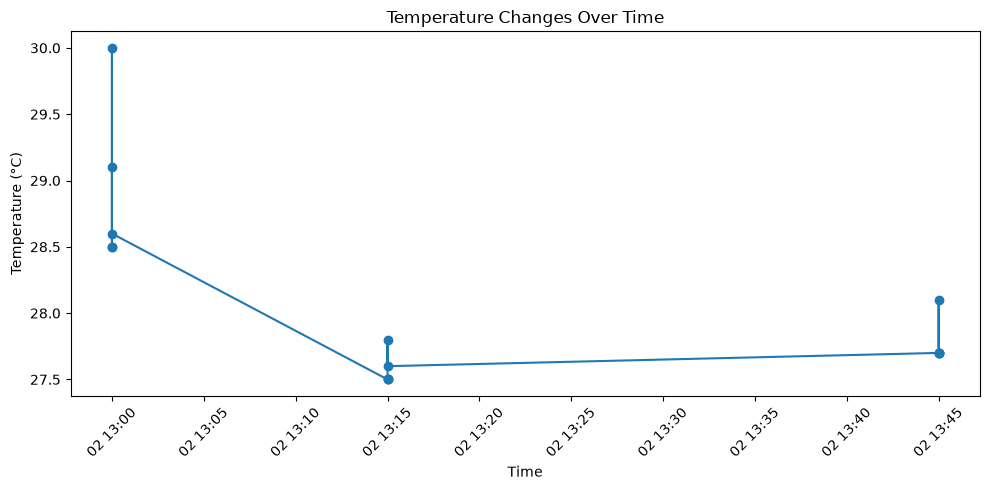

In [16]:
plt.figure(figsize=(10,5))

plt.plot(
    df["time"],
    df["temperature_c"],
    marker="o"
)

plt.title("Temperature Changes Over Time")
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

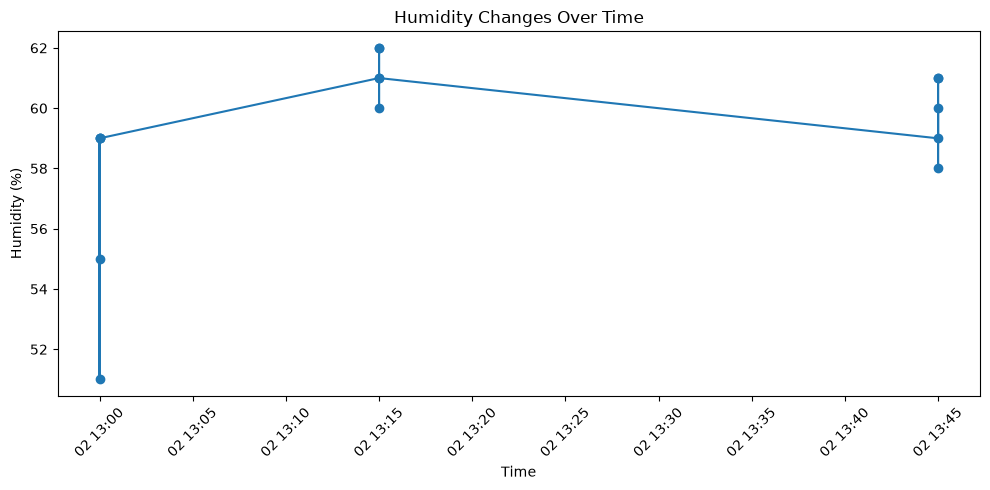

In [17]:
plt.figure(figsize=(10,5))

plt.plot(
    df["time"],
    df["humidity_percent"],
    marker="o"
)

plt.title("Humidity Changes Over Time")
plt.xlabel("Time")
plt.ylabel("Humidity (%)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

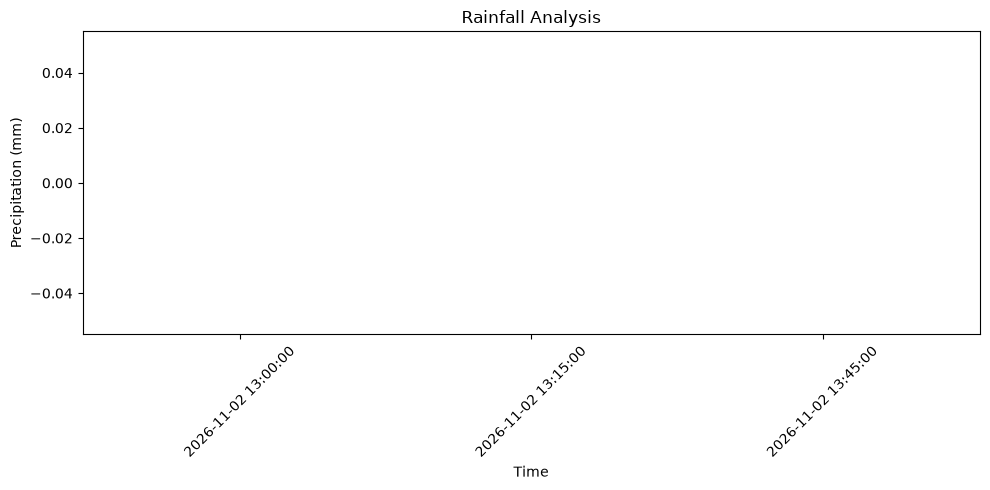

In [18]:
plt.figure(figsize=(10,5))

plt.bar(
    df["time"].astype(str),
    df["precipitation_mm"]
)

plt.title("Rainfall Analysis")
plt.xlabel("Time")
plt.ylabel("Precipitation (mm)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

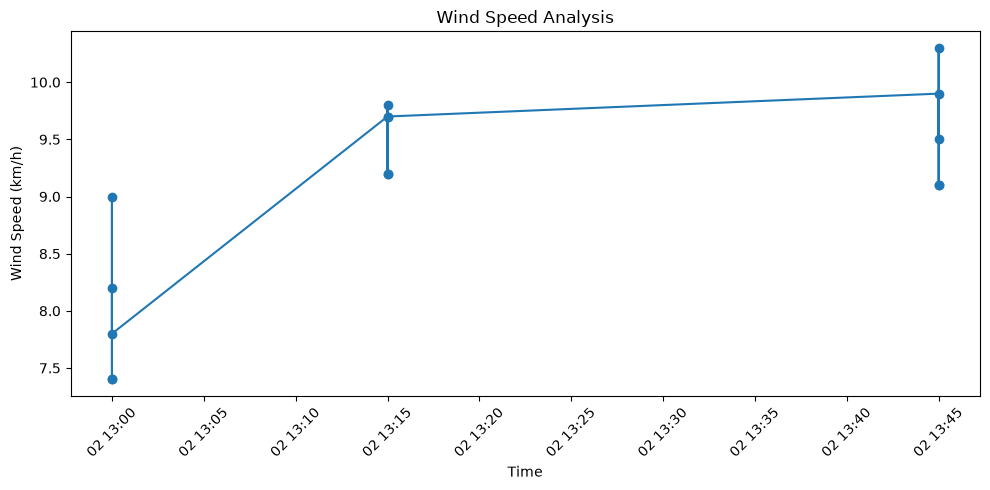

In [19]:

plt.figure(figsize=(10,5))

plt.plot(
    df["time"],
    df["wind_speed_kmh"],
    marker="o"
)

plt.title("Wind Speed Analysis")
plt.xlabel("Time")
plt.ylabel("Wind Speed (km/h)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

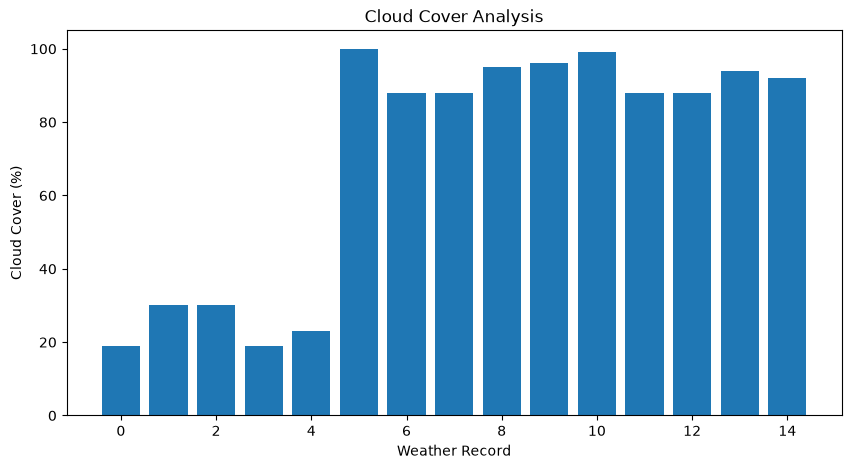

In [20]:
plt.figure(figsize=(10,5))

plt.bar(
    range(len(df)),
    df["cloud_cover_percent"]
)

plt.title("Cloud Cover Analysis")
plt.xlabel("Weather Record")
plt.ylabel("Cloud Cover (%)")

plt.show()

In [24]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

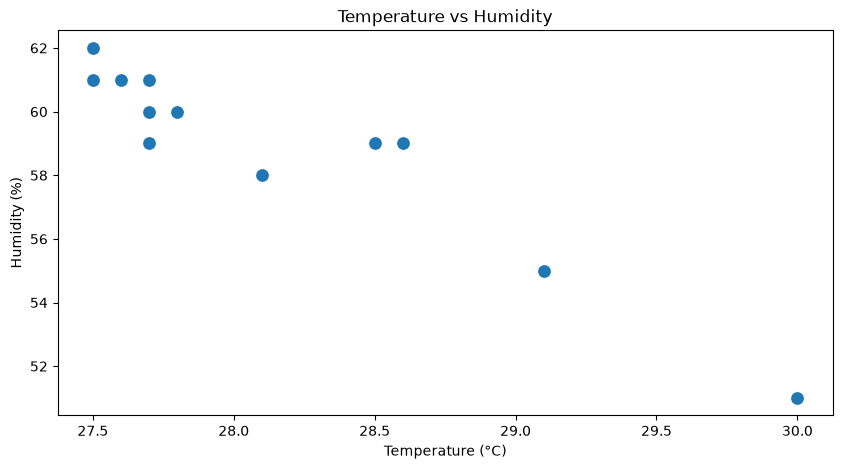

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="temperature_c",
    y="humidity_percent",
    s=100
)

plt.title("Temperature vs Humidity")
plt.xlabel("Temperature (°C)")
plt.ylabel("Humidity (%)")

plt.show()

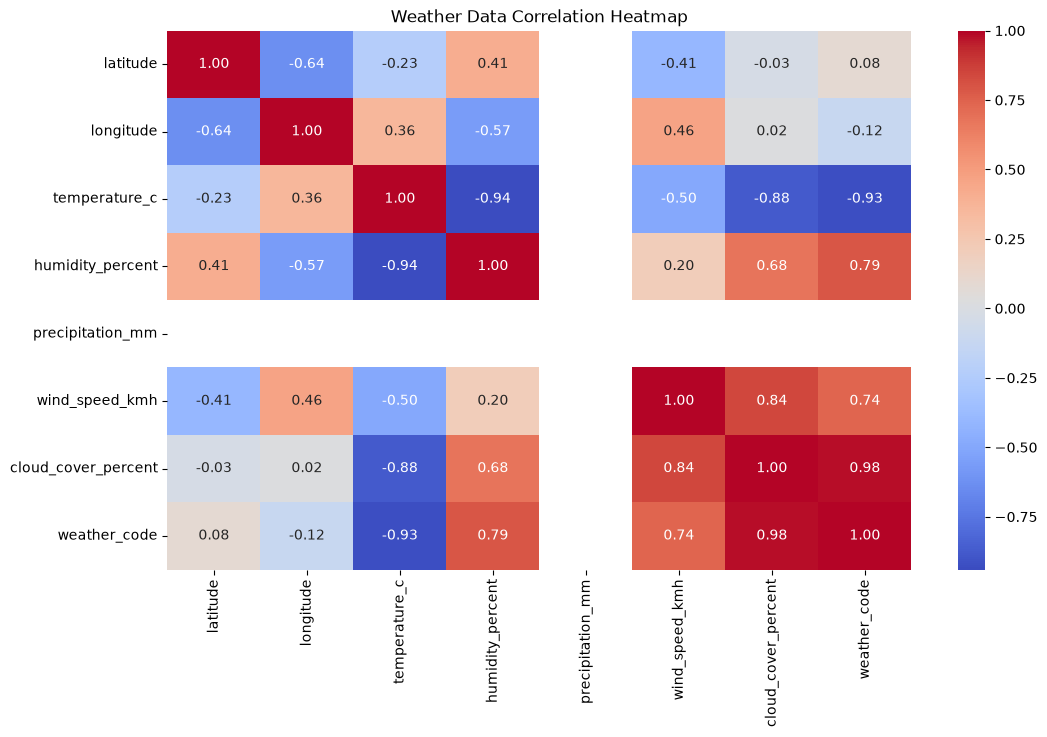

In [30]:
plt.figure(figsize=(12,7))

correlation = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Weather Data Correlation Heatmap")

plt.show()

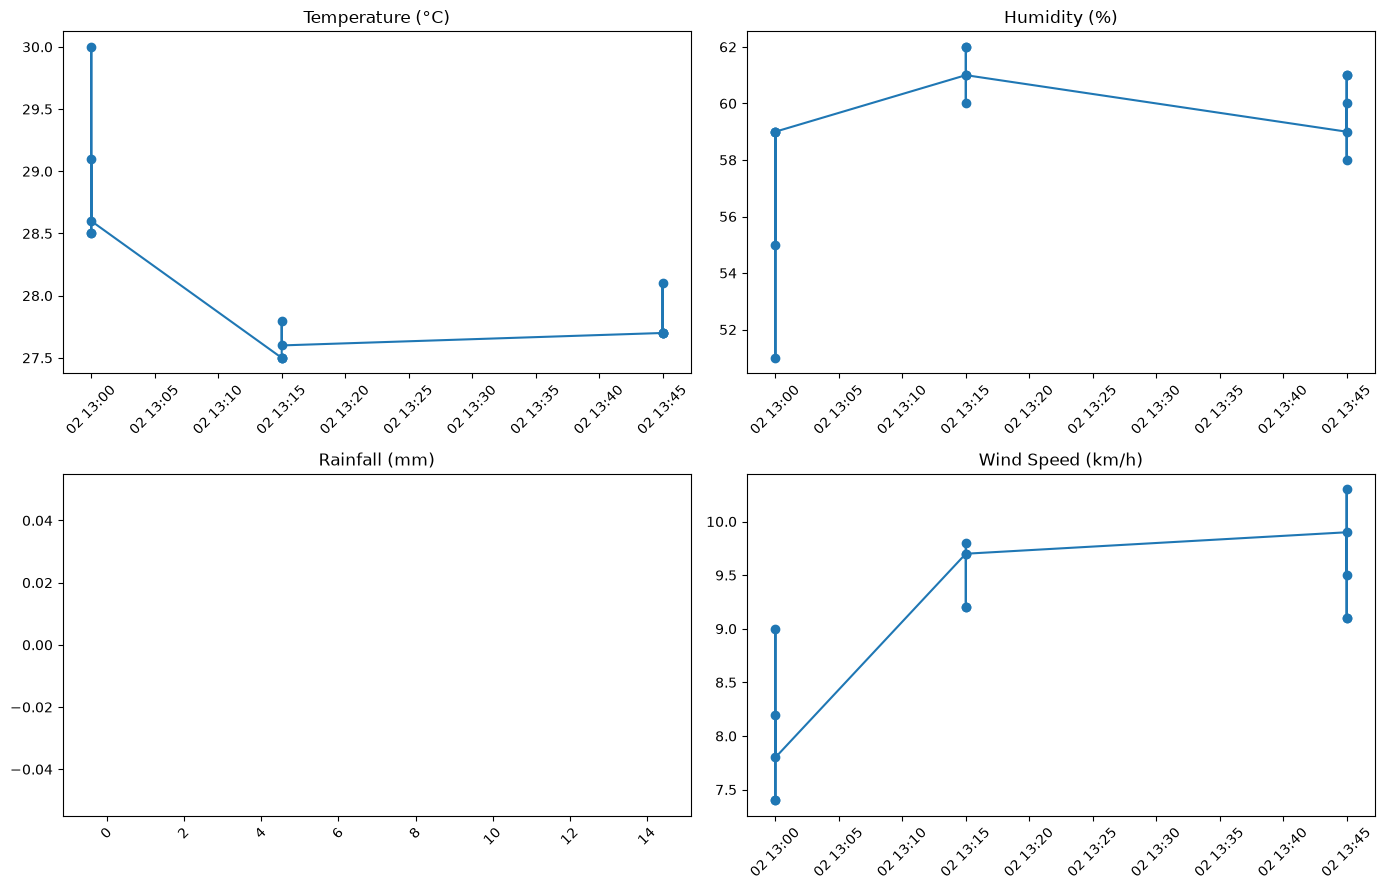

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0,0].plot(
    df["time"], df["temperature_c"], marker="o"
)
axes[0,0].set_title("Temperature (°C)")

axes[0,1].plot(
    df["time"], df["humidity_percent"], marker="o"
)
axes[0,1].set_title("Humidity (%)")

axes[1,0].bar(
    range(len(df)), df["precipitation_mm"]
)
axes[1,0].set_title("Rainfall (mm)")

axes[1,1].plot(
    df["time"], df["wind_speed_kmh"], marker="o"
)
axes[1,1].set_title("Wind Speed (km/h)")

for ax in axes.flat:
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [32]:
print("=" * 55)
print("          WEATHER DATA ANALYSIS REPORT")
print("=" * 55)

print("\nLOCATION:", df["location"].mode()[0])

print("\nTOTAL WEATHER RECORDS:", len(df))

print("\nTEMPERATURE")
print("Average:", round(df["temperature_c"].mean(), 2), "°C")
print("Maximum:", df["temperature_c"].max(), "°C")
print("Minimum:", df["temperature_c"].min(), "°C")

print("\nHUMIDITY")
print("Average:", round(df["humidity_percent"].mean(), 2), "%")

print("\nRAINFALL")
print("Total:", round(df["precipitation_mm"].sum(), 2), "mm")

print("\nWIND SPEED")
print("Average:", round(df["wind_speed_kmh"].mean(), 2), "km/h")

print("\nCLOUD COVER")
print("Average:", round(df["cloud_cover_percent"].mean(), 2), "%")

print("\n" + "=" * 55)
print("          ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 55)

          WEATHER DATA ANALYSIS REPORT

LOCATION: Hadapsar

TOTAL WEATHER RECORDS: 15

TEMPERATURE
Average: 28.1 °C
Maximum: 30.0 °C
Minimum: 27.5 °C

HUMIDITY
Average: 59.2 %

RAINFALL
Total: 0.0 mm

WIND SPEED
Average: 9.02 km/h

CLOUD COVER
Average: 69.93 %

          ANALYSIS COMPLETED SUCCESSFULLY


In [33]:
df.to_csv(
    "Cleaned_Weather_Data.csv",
    index=False
)

print("Cleaned weather dataset saved successfully!")

Cleaned weather dataset saved successfully!
